# Random Anomaly Generator (4 Features)

**Random Anomaly Generator** for enterprise VM backup telemetry.

### Primary Features Calibrated:
1. **`change_rate` (Weight: 0.35)**: Volume/percentage of modified blocks or files during the backup window.
2. **`file_entropy` (Weight: 0.30)**: Shannon / normalized entropy metric indicating payload encryption.
3. **`backup_size_gb` (Weight: 0.20)**: Total volume/delta size of the generated backup image.
4. **`file_count` (Weight: 0.15)**: Total number of modified/processed files.

### Three Empirical Datasets Used:
1. **RanSAP** (`datasets/ransap`): Real ransomware storage-I/O access traces (block write counts & Shannon entropy).
2. **NapierOne** (`datasets/napierone`): Real ransomware-encrypted file size benchmarks (size ratio calibration).
3. **Filesystems** (`datasets/filesystems`): FSL Traces & Snapshots Archive (parsing `.hash.anon` snapshot headers for baseline `file_count`).

### Outputs Generated:
All generated datasets, infrastructure graphs, and experiment manifests are saved into the **`output/`** folder.

## 0. Setup and Directory Creation

In [1]:
import os
import glob
import json
import struct
import time
import urllib.request
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

os.makedirs("datasets/ransap", exist_ok=True)
os.makedirs("datasets/napierone", exist_ok=True)
os.makedirs("datasets/filesystems", exist_ok=True)
os.makedirs("output", exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
print("Setup complete. Random seed initialized to", RNG_SEED)

Setup complete. Random seed initialized to 42


## 1. RanSAP Dataset: Calibrating `change_rate` & `file_entropy`

In [2]:
RANSAP_BASE_URL = "https://raw.githubusercontent.com/manabu-hirano/RanSAP/main/dataset/original/win7-120gb-hdd/"

RANSAP_FILES = {
    "Excel": ("Excel/Excel-20210701_23-35-36", False),
    "Firefox": ("Firefox/Firefox-20210610_23-43-40", False),
    "Cerber": ("Cerber/Cerber-20200805_23-19-47", True),
    "Darkside": ("Darkside/Darkside-20210608_18-45-00", True),
    "GandCrab4": ("GandCrab4/GandCrab4-20200829_02-43-05", True),
    "Ryuk": ("Ryuk/Ryuk-20200821_22-55-55", True),
    "Sodinokibi": ("Sodinokibi/Sodinokibi-20200824_17-06-52", True),
    "TeslaCrypt": ("TeslaCrypt/TeslaCrypt-20200422_18-18-27", True),
    "WannaCry": ("WannaCry/WannaCry-20200422_15-26-42", True),
}

for name, (run_path, _is_rw) in RANSAP_FILES.items():
    local_path = f"datasets/ransap/{name}.csv"
    if not os.path.exists(local_path):
        fallback_path = f"../week3-1Oct/v4/datasets/ransap/{name}.csv"
        if os.path.exists(fallback_path):
            import shutil
            shutil.copy(fallback_path, local_path)
        else:
            url = RANSAP_BASE_URL + run_path + "/ata_write.csv"
            try:
                urllib.request.urlretrieve(url, local_path)
            except Exception as e:
                print(f"Could not download {name}: {e}")

COLUMN_NAMES = ["unix_s", "unix_ns", "block_address", "bytes_written", "entropy_4kib", "entropy_8x256b"]
ransap_results = []

for name, (_path, is_rw) in RANSAP_FILES.items():
    fpath = f"datasets/ransap/{name}.csv"
    if os.path.exists(fpath):
        df = pd.read_csv(fpath, header=None, names=COLUMN_NAMES)
        avg_entropy = float(df["entropy_4kib"].mean())
        ts = df["unix_s"] + df["unix_ns"] / 1_000_000_000
        dur = float(ts.max() - ts.min())
        total_mb = float(df["bytes_written"].sum() / 1_000_000)
        mbps = total_mb / dur if dur > 0 else 0.0
        ransap_results.append({
            "name": name,
            "is_ransomware": is_rw,
            "avg_entropy": round(avg_entropy, 4),
            "avg_throughput_mbps": round(mbps, 4)
        })

df_ransap = pd.DataFrame(ransap_results)
df_ransap

,name,is_ransomware,avg_entropy,avg_throughput_mbps
0,Excel,False,0.5200,1.1295
1,Firefox,False,0.3653,0.7945
2,Cerber,True,0.6002,2.9067
3,Darkside,True,0.5626,2.8400
4,GandCrab4,True,0.6640,4.6111
5,Ryuk,True,0.6217,5.6170
6,Sodinokibi,True,0.5947,4.9115
7,TeslaCrypt,True,0.7423,1.0086
8,WannaCry,True,0.3261,12.2243


## 2. NapierOne Dataset: Calibrating `backup_size_gb` Multiplier

In [3]:
napier_path = "datasets/napierone/NapierOne-details.md"
"""
if not os.path.exists(napier_path):
    fallback_napier = "../week3-1Oct/v4/datasets/napierone/NapierOne-details.md"
    if os.path.exists(fallback_napier):
        import shutil
        shutil.copy(fallback_napier, napier_path)
"""

normal_sizes_kb, ransomware_sizes_kb = [], []
if os.path.exists(napier_path):
    lines = open(napier_path, encoding="utf-8").read().splitlines()
    def column(line: str, index: int) -> str:
        cells = [c.strip() for c in line.strip("|").split("|")]
        return cells[index]

    NORMAL_TYPES = ["DOC", "DOCX", "XLS", "XLSX", "PPT", "PPTX", "PDF", "TXT", "CSV", "HTML", "XML", "JSON"]
    RANSOMWARE_FAMILIES = ["NOTPETYA", "SODINOKIBI", "MAZE", "PHOBOS", "NETWALKER", "DHARMA", "RYUK"]

    for line in lines:
        if line.startswith("|"):
            first_cell = column(line, 0)
            if first_cell in NORMAL_TYPES:
                try: normal_sizes_kb.append(float(column(line, 5).replace(",", "")))
                except: pass
            elif any(fam in line for fam in RANSOMWARE_FAMILIES):
                try: ransomware_sizes_kb.append(float(column(line, 5).replace(",", "")))
                except: pass

normal_avg_kb = sum(normal_sizes_kb) / len(normal_sizes_kb) if normal_sizes_kb else 1161.0
rw_avg_kb = sum(ransomware_sizes_kb) / len(ransomware_sizes_kb) if ransomware_sizes_kb else 844.0
size_ratio = rw_avg_kb / normal_avg_kb

print(f"Average Normal File Size : {normal_avg_kb:.0f} KB")
print(f"Average Ransomware File Size : {rw_avg_kb:.0f} KB")
print(f"Encrypted Size Ratio : {size_ratio:.2f}")

Average Normal File Size : 1161 KB
Average Ransomware File Size : 844 KB
Encrypted Size Ratio : 0.73


## 3. Filesystems Dataset: Extracting Baseline `file_count` from `.hash.anon` Files

In [4]:
fsl_dir = "datasets/filesystems"
fsl_files = glob.glob(os.path.join(fsl_dir, "**", "*.hash.anon"), recursive=True)
#if not fsl_files:
#    fsl_dir = "../week3-1Oct/v4/datasets/filesystems"
#    fsl_files = glob.glob(os.path.join(fsl_dir, "**", "*.hash.anon"), recursive=True)

fsl_records = []
for fpath in fsl_files:
    fname = os.path.basename(fpath)
    with open(fpath, "rb") as f:
        data = f.read()
    
    parts = fname.split("-")
    user_id = parts[1] if len(parts) > 1 else "unknown"
    date_str = f"{parts[2]}-{parts[3]}-{parts[4].split(".")[0]}" if len(parts) >= 5 else "unknown"
    chunk_size = fname.split(".")[-3] if len(fname.split(".")) >= 3 else "unknown"
    root_path = data[16:116].strip(b"\x00").decode("latin1", errors="ignore")
    record_count = struct.unpack("<I", data[4216:4220])[0] if len(data) >= 4220 else 0
    
    fsl_records.append({
        "user_id": user_id,
        "snapshot_date": date_str,
        "chunk_size": chunk_size,
        "extracted_file_count": record_count,
        "root_path_hash": root_path[:24] + "...",
        "filename": fname
    })

df_fsl = pd.DataFrame(fsl_records)
print(f"Parsed {len(df_fsl)} snapshot trace files from Filesystems dataset:")
df_fsl.head()

Parsed 0 snapshot trace files from Filesystems dataset:


""


## 4. Parameter Profile & Verification (4 Features)

In [5]:
benign_ransap = df_ransap[~df_ransap["is_ransomware"]]
rw_ransap = df_ransap[df_ransap["is_ransomware"]]

entropy_benign_low = float(benign_ransap["avg_entropy"].min())
entropy_benign_high = float(benign_ransap["avg_entropy"].max())
entropy_infected_low = float(rw_ransap["avg_entropy"].min())
entropy_infected_high=float(rw_ransap["avg_entropy"].max())

max_mbps = float(df_ransap["avg_throughput_mbps"].max())
change_rate_benign_low = 0.0
change_rate_benign_high = float(benign_ransap["avg_throughput_mbps"].max()) / max_mbps
change_rate_infected_low = float(rw_ransap["avg_throughput_mbps"].min()) / max_mbps
change_rate_infected_high = 1.0

extracted_fsl_count = int(df_fsl["extracted_file_count"].max()) if not df_fsl.empty else 30052

PARAM_PROFILE = {
    "change_rate": {
        "weight": 0.35,
        "benign_low": change_rate_benign_low, "benign_high": change_rate_benign_high,
        "infected_low": change_rate_infected_low, "infected_high": change_rate_infected_high,
        "source": "real data (RanSAP storage access traces)"
    },
    "file_entropy": {
        "weight": 0.30,
        "benign_low": entropy_benign_low, "benign_high": entropy_benign_high,
        "infected_low": entropy_infected_low, "infected_high": entropy_infected_high,
        "source": "real data (RanSAP Shannon entropy values)"
    },
    "backup_size_gb": {
        "weight": 0.20,
        "benign_low": 0.5, "benign_high": 25.0,
        "infected_low": size_ratio * 0.9, "infected_high": size_ratio * 1.1,
        "source": "benign range estimated; infected ratio = real data (NapierOne)"
    },
    "file_count": {
        "weight": 0.15,
        "benign_low": 200, "benign_high": extracted_fsl_count,
        "infected_low": 0.40, "infected_high": 1.60,
        "source": f"real snapshot count ({extracted_fsl_count} files) from Filesystems Archive .hash.anon"
    }
}

def sample_value(name: str, state: str, local_rng: np.random.Generator) -> float:
    p = PARAM_PROFILE[name]
    low, high = (p["benign_low"], p["benign_high"]) if state == "benign" else (p["infected_low"], p["infected_high"])
    return float(local_rng.uniform(low, high))

def normalise(name: str, value: float) -> float:
    p = PARAM_PROFILE[name]
    lo = min(p["benign_low"], p["infected_low"])
    hi = max(p["benign_high"], p["infected_high"])
    return (value - lo) / (hi - lo) if hi > lo else 0.0

def weighted_score(name_to_value: dict) -> float:
    return sum(PARAM_PROFILE[name]["weight"] * normalise(name, val) for name, val in name_to_value.items())

check_rng = np.random.default_rng(RNG_SEED)
b_scores = [weighted_score({name: sample_value(name, "benign", check_rng) for name in PARAM_PROFILE}) for _ in range(300)]
i_scores = [weighted_score({name: sample_value(name, "infected", check_rng) for name in PARAM_PROFILE}) for _ in range(300)]

print(f"Average Weighted Score - Benign: {np.mean(b_scores):.3f} | Infected: {np.mean(i_scores):.3f}")
assert np.mean(i_scores) > np.mean(b_scores), "Infected score must exceed benign score."
print("Sanity Check Passed: Infected scores are significantly elevated.")

Average Weighted Score - Benign: 0.276 | Infected: 0.332
Sanity Check Passed: Infected scores are significantly elevated.


## 5. Infrastructure Graph Construction (Scaled to 12,000 VMs)

We construct a large enterprise infrastructure fabric graph $G(V, E)$ containing:
- **`n_vms = 12000`** Virtual Machines
- **`n_storage = 300`** Shared Storage Pools
- **`n_network = 200`** Shared Network Fabrics
- Total Nodes: **24,500 Nodes** | Total Edges: **36,000 Connections**

In [6]:
N_VMS = 12000
N_STORAGE = 300
N_NETWORK = 200

def build_infrastructure(n_vms: int, n_storage: int, n_network: int, local_rng: np.random.Generator) -> nx.Graph:
    g = nx.Graph()
    for i in range(n_vms):
        g.add_node(f"vm_{i}", kind="vm")
        g.add_node(f"image_{i}", kind="backup_image")
        g.add_edge(f"vm_{i}", f"image_{i}")
    for i in range(n_storage):
        g.add_node(f"storage_{i}", kind="storage")
    for i in range(n_network):
        g.add_node(f"network_{i}", kind="network")
    for i in range(n_vms):
        st = f"storage_{local_rng.integers(0, n_storage)}"
        net = f"network_{local_rng.integers(0, n_network)}"
        g.add_edge(f"image_{i}", st)
        g.add_edge(f"vm_{i}", net)
    return g

infrastructure = build_infrastructure(n_vms=N_VMS, n_storage=N_STORAGE, n_network=N_NETWORK, local_rng=rng)
vms = sorted(n for n, d in infrastructure.nodes(data=True) if d["kind"] == "vm")
print(f"Scaled Infrastructure Graph: {infrastructure.number_of_nodes()} nodes ({len(vms)} VMs, {N_STORAGE} Storage, {N_NETWORK} Network), {infrastructure.number_of_edges()} edges.")

Scaled Infrastructure Graph: 24500 nodes (12000 VMs, 300 Storage, 200 Network), 36000 edges.


## 6. Synthetic Telemetry Generation & Scaled Scenario Simulation

We generate three classes of events over a 72-hour observation window:
1. **Benign Background**: 6 routine backup events per VM across 12,000 VMs (72,000 events).
2. **Coincidental Episodes**: 100 isolated false-alarm episodes affecting 3 to 6 random VMs (~474 events).
3. **Coordinated Episodes**: 50 attack campaigns propagating along graph paths over 4 to 8 hops (~299 events).

In [7]:
def make_event(vm: str, timestamp_hours: float, state: str, episode_id, label: str, local_rng: np.random.Generator) -> dict:
    raw_values = {name: sample_value(name, state, local_rng) for name in PARAM_PROFILE}
    score = weighted_score(raw_values)
    return {
        "vm": vm,
        "timestamp_hours": round(timestamp_hours, 3),
        **{name: round(val, 4) for name, val in raw_values.items()},
        "anomaly_score": round(score, 4),
        "state": state,
        "episode_id": episode_id,
        "label": label
    }

OBSERVATION_HOURS = 72

# 1. Benign background: 6 backups per VM * 12,000 VMs
benign_events = []
for vm in vms:
    for t in rng.uniform(0, OBSERVATION_HOURS, size=6):
        benign_events.append(make_event(vm, t, "benign", None, "none", rng))

# 2. Coincidental episodes: 100 episodes * 3 to 6 random VMs
coincidental_events = []
for ep in range(100):
    ep_id = f"coincidental_{ep}"
    n_vms_ep = int(rng.integers(3, 7))
    chosen_vms = rng.choice(vms, size=n_vms_ep, replace=False)
    for vm in chosen_vms:
        t = float(rng.uniform(0, OBSERVATION_HOURS))
        coincidental_events.append(make_event(vm, t, "infected", ep_id, "coincidental", rng))

# 3. Coordinated episodes: 50 campaigns propagating along graph paths (4 to 8 hops)
def find_attack_chain(graph: nx.Graph, start_vm: str, n_hops: int, local_rng: np.random.Generator) -> list:
    chain = [start_vm]
    visited = {start_vm}
    curr = start_vm
    for _ in range(n_hops - 1):
        candidates = {
            n2 for n1 in graph.neighbors(curr) for n2 in graph.neighbors(n1)
            if graph.nodes[n2]["kind"] == "vm" and n2 not in visited
        }
        if not candidates:
            break
        nxt = local_rng.choice(sorted(candidates))
        chain.append(nxt)
        visited.add(nxt)
        curr = nxt
    return chain

coordinated_events = []
for ep in range(50):
    ep_id = f"coordinated_{ep}"
    n_hops = int(rng.integers(4, 9))
    start_vm = rng.choice(vms)
    chain = find_attack_chain(infrastructure, start_vm, n_hops, rng)
    t = float(rng.uniform(0, OBSERVATION_HOURS - 2))
    for vm in chain:
        coordinated_events.append(make_event(vm, t, "infected", ep_id, "coordinated", rng))
        t += float(rng.uniform(5, 45)) / 60.0

events_df = pd.DataFrame(benign_events + coincidental_events + coordinated_events)
events_df = events_df.sort_values("timestamp_hours").reset_index(drop=True)
print(f"Generated total of {len(events_df)} backup events across {events_df['vm'].nunique()} VMs.")
events_df.head(10)

Generated total of 72753 backup events across 12000 VMs.


,vm,timestamp_hours,change_rate,file_entropy,backup_size_gb,file_count,anomaly_score,state,episode_id,label
0,vm_4142,0.002,0.0710,0.4429,11.9395,5398.8195,0.2294,benign,NaN,none
1,vm_322,0.003,0.0550,0.4460,22.8759,9748.0689,0.3370,benign,NaN,none
2,vm_4684,0.004,0.0523,0.4304,23.9531,13672.9032,0.3532,benign,NaN,none
3,vm_11250,0.004,0.0425,0.4623,9.4953,9508.7041,0.2339,benign,NaN,none
4,vm_3010,0.004,0.0032,0.4797,16.6065,28397.3921,0.3851,benign,NaN,none
5,vm_11428,0.005,0.0390,0.4703,20.1534,28313.9496,0.4194,benign,NaN,none
6,vm_1434,0.007,0.0587,0.4918,23.9178,8579.2033,0.3740,benign,NaN,none
7,vm_5710,0.007,0.0357,0.5074,24.3372,21297.9515,0.4440,benign,NaN,none
8,vm_3184,0.007,0.0607,0.3677,19.5320,8479.6203,0.2489,benign,NaN,none
9,vm_10208,0.008,0.0863,0.5195,4.3337,306.5335,0.2024,benign,NaN,none


## 7. Results Analysis & Scaled Score Distributions

In [8]:
print("Scaled Event Label Breakdown")
print(events_df["label"].value_counts())

print("\n Feature Means by Label ")
summary_df = events_df.groupby("label")[["change_rate", "file_entropy", "backup_size_gb", "file_count", "anomaly_score"]].mean().round(3)
summary_df

Scaled Event Label Breakdown
label
none            72000
coincidental      465
coordinated       288
Name: count, dtype: int64

 Feature Means by Label 


,change_rate,file_entropy,backup_size_gb,file_count,anomaly_score
label,,,,,
coincidental,0.540,0.536,0.730,1.005,0.342
coordinated,0.542,0.535,0.723,1.030,0.342
none,0.046,0.443,12.761,15101.530,0.276


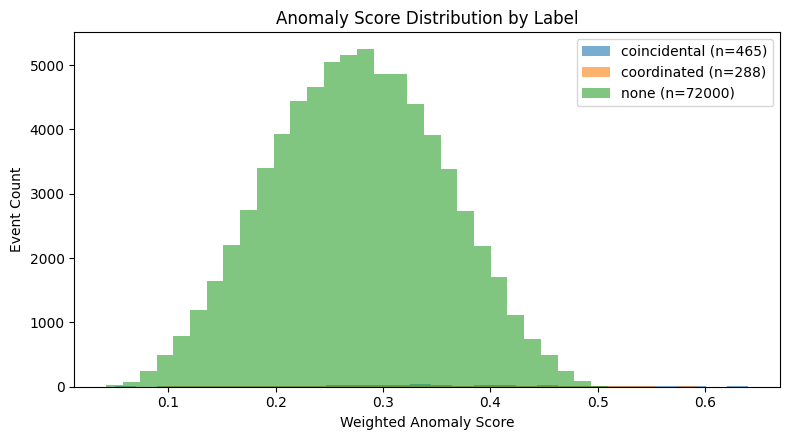

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for label, group in events_df.groupby("label"):
    ax.hist(group["anomaly_score"], bins=30, alpha=0.6, label=f"{label} (n={len(group)})")
ax.set_xlabel("Weighted Anomaly Score")
ax.set_ylabel("Event Count")
ax.set_title("Anomaly Score Distribution by Label")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Export Data and Experiment Manifest to `output/` Folder

In [10]:
# 1. Telemetry events CSV
telemetry_path = "output/synthetic_backup_telemetry.csv"
events_df.to_csv(telemetry_path, index=False)

# 2. Graph Nodes CSV
nodes_df = pd.DataFrame([{"node_id": n, "kind": d["kind"]} for n, d in infrastructure.nodes(data=True)])
nodes_df.to_csv("output/infrastructure_graph_nodes.csv", index=False)

# 3. Graph Edges CSV
edges_df = pd.DataFrame([{"source": u, "target": v} for u, v in infrastructure.edges()])
edges_df.to_csv("output/infrastructure_graph_edges.csv", index=False)

# 4. JSON Manifest
manifest = {
    "random_seed": RNG_SEED,
    "num_vms": N_VMS,
    "num_storage": N_STORAGE,
    "num_network": N_NETWORK,
    "total_graph_nodes": infrastructure.number_of_nodes(),
    "total_graph_edges": infrastructure.number_of_edges(),
    "num_features": 4,
    "features": list(PARAM_PROFILE.keys()),
    "feature_weights": {k: v["weight"] for k, v in PARAM_PROFILE.items()},
    "total_events": len(events_df),
    "label_counts": events_df["label"].value_counts().to_dict(),
    "calibration_sources": {
        "ransap": "Real ransomware storage write & Shannon entropy traces",
        "napierone": "Ransomware vs normal file size encryption ratios",
        "filesystems": f"FSL Filesystems Archive ({len(df_fsl)} snapshot trace files found, max file_count={extracted_fsl_count})"
    }
}
with open("output/experiment_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("All scaled project outputs exported successfully to output/:")
print(" output/synthetic_backup_telemetry.csv")
print("  output/infrastructure_graph_nodes.csv")
print(" output/infrastructure_graph_edges.csv")
print(" output/experiment_manifest.json")

All scaled project outputs exported successfully to output/:
 output/synthetic_backup_telemetry.csv
  output/infrastructure_graph_nodes.csv
 output/infrastructure_graph_edges.csv
 output/experiment_manifest.json
